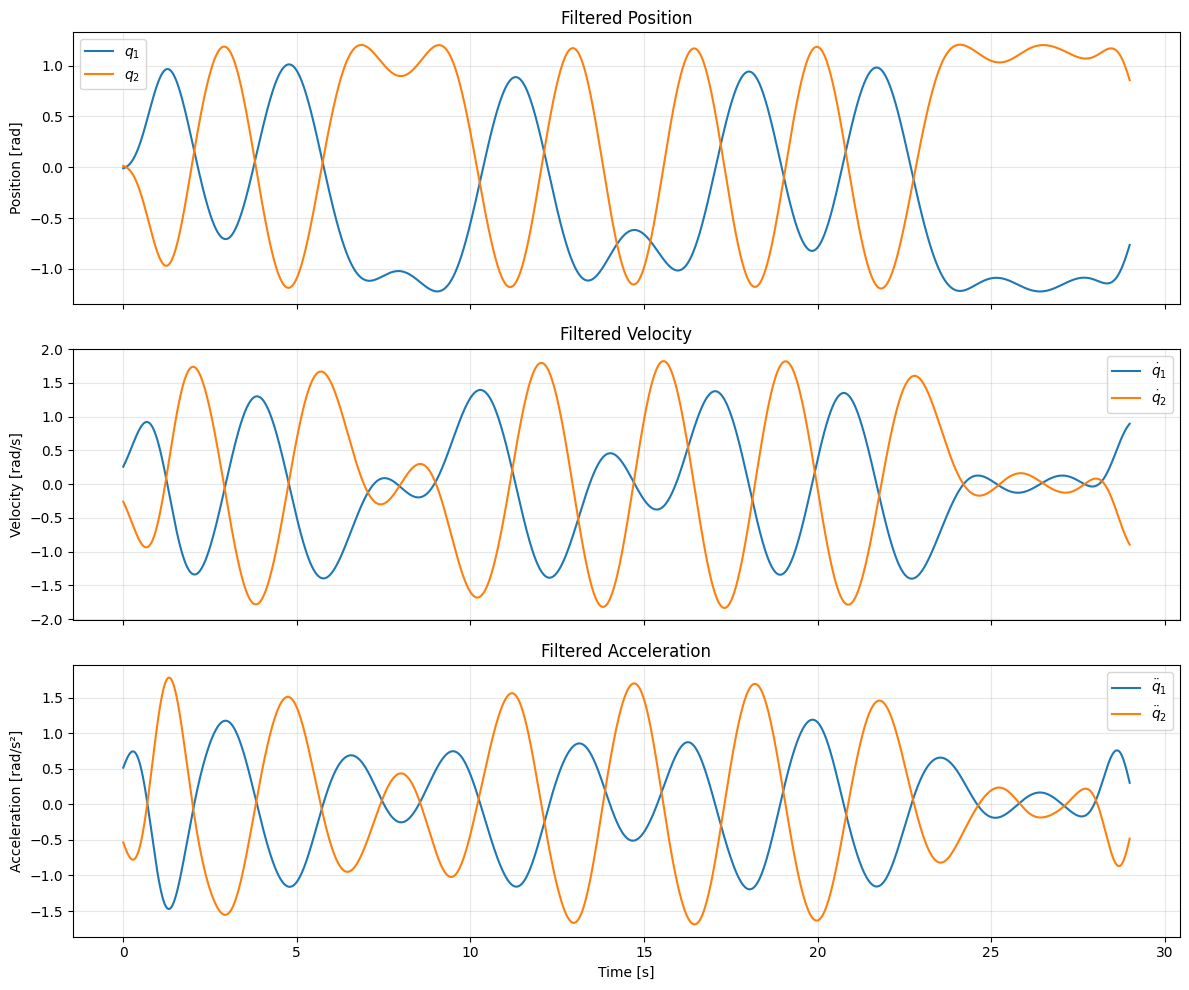

In [179]:
import numpy as np
from scipy.io import loadmat
import matplotlib.pyplot as plt


def dataset_to_iddata(dataset):
    """
    Load real-robot dataset from .mat into a flat dict.
    All filtering is already done in MATLAB — just unpack.
    """
    runs = dataset.runs
    if not isinstance(runs, np.ndarray):
        runs = np.array([runs])

    R = runs.size

    # First pass: total number of samples
    Ni = np.zeros(R, dtype=int)
    for i in range(R):
        Ni[i] = np.asarray(runs[i].y_filt).shape[0]
    Ntot = Ni.sum()

    # Preallocate
    data = {}
    data["t"]        = np.zeros(Ntot)
    data["q"]        = np.zeros((2, Ntot))
    data["qd"]       = np.zeros((2, Ntot))
    data["qdd"]      = np.zeros((2, Ntot))
    data["tau_meas"] = np.zeros((2, Ntot))

    # Assume constant dt across runs
    ti0 = np.asarray(runs[0].time).ravel()
    dt = ti0[1] - ti0[0]
    data["dt"] = float(dt)

    idx0 = 0
    for i in range(R):
        r = runs[i]
        ti = np.asarray(r.time).ravel()
        Ni_i = Ni[i]
        s = idx0
        e = idx0 + Ni_i

        y_filt = np.asarray(r.y_filt)       # (N, 4): [q1, q2, qd1, qd2]
        ddq    = np.asarray(r.ddq)           # (N, 2): [qdd1, qdd2]
        tau    = np.asarray(r.u_applied)     # (N, 2): [tau1, tau2] #FILTERED
        # tau    = np.asarray(r.u_cmd_noisy)     # (N, 2): [tau1, tau2] #UNFILTERED
        

        data["t"][s:e]        = ti[:Ni_i]
        data["q"][:, s:e]     = y_filt[:Ni_i, 0:2].T
        data["qd"][:, s:e]    = y_filt[:Ni_i, 2:4].T
        data["qdd"][:, s:e]   = ddq[:Ni_i, :].T
        data["tau_meas"][:, s:e] = tau[:Ni_i, :].T

        idx0 = e

    return data


def plot_data(data, run_length):
    """Quick sanity plot for the first run."""
    idx = slice(0, run_length)
    t = data['t'][idx]

    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    colors = ['#1f77b4', '#ff7f0e']

    axes[0].plot(t, data['q'][0, idx], color=colors[0], label='$q_1$')
    axes[0].plot(t, data['q'][1, idx], color=colors[1], label='$q_2$')
    axes[0].set_ylabel('Position [rad]')
    axes[0].set_title('Filtered Position')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(t, data['qd'][0, idx], color=colors[0], label=r'$\dot{q}_1$')
    axes[1].plot(t, data['qd'][1, idx], color=colors[1], label=r'$\dot{q}_2$')
    axes[1].set_ylabel('Velocity [rad/s]')
    axes[1].set_title('Filtered Velocity')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    axes[2].plot(t, data['qdd'][0, idx], color=colors[0], label=r'$\ddot{q}_1$')
    axes[2].plot(t, data['qdd'][1, idx], color=colors[1], label=r'$\ddot{q}_2$')
    axes[2].set_ylabel('Acceleration [rad/s²]')
    axes[2].set_xlabel('Time [s]')
    axes[2].set_title('Filtered Acceleration')
    axes[2].legend(); axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    S = loadmat("planar_2dof_dataset_real.mat",
                squeeze_me=True, struct_as_record=False)
    dataset = S["dataset"]

    data = dataset_to_iddata(dataset)

    # Get length of first run for plotting
    runs = dataset.runs
    if not isinstance(runs, np.ndarray):
        runs = np.array([runs])
    run_length = np.asarray(runs[0].y_filt).shape[0]

    plot_data(data, run_length)


In [180]:
runs = dataset.runs
if not isinstance(runs, np.ndarray):
    runs = np.array([runs])

trajectories = {"time": data["t"], "states": []}

for i, r in enumerate(runs):
    y_filt = np.asarray(r.y_filt)       # (N, 4)
    tau    = np.asarray(r.u_applied)     # (N, 2)
    Ni = y_filt.shape[0]
    print(f"Processing run {i+1} with {Ni} samples...")

    theta1  = y_filt[:, 0]
    theta2  = y_filt[:, 1]
    dtheta1 = y_filt[:, 2]
    dtheta2 = y_filt[:, 3]
    tau1    = tau[:, 0]
    tau2    = tau[:, 1]

    trajectories["states"].append({
        "initial_condition": y_filt[0, :],
        "theta1": theta1,
        "theta2": theta2,
        "dtheta1": dtheta1,
        "dtheta2": dtheta2,
        "tau1": tau1,
        "tau2": tau2,
    })

trajectories["states"]


Processing run 1 with 2900 samples...
Processing run 2 with 1400 samples...
Processing run 3 with 4400 samples...
Processing run 4 with 1900 samples...
Processing run 5 with 8900 samples...
Processing run 6 with 3900 samples...
Processing run 7 with 2900 samples...
Processing run 8 with 4900 samples...
Processing run 9 with 2400 samples...
Processing run 10 with 3900 samples...


[{'initial_condition': array([-0.01042416,  0.01318048,  0.25824712, -0.25974313]),
  'theta1': array([-0.01042416, -0.00933454, -0.00813692, ..., -0.78736513,
         -0.77616468, -0.76487879], shape=(2900,)),
  'theta2': array([0.01318048, 0.01215889, 0.01102623, ..., 0.88000828, 0.86872268,
         0.8573001 ], shape=(2900,)),
  'dtheta1': array([0.25824712, 0.26855305, 0.27903987, ..., 0.88189924, 0.88802344,
         0.8938345 ], shape=(2900,)),
  'dtheta2': array([-0.25974313, -0.27037451, -0.28119782, ..., -0.87640149,
         -0.88565097, -0.8945962 ], shape=(2900,)),
  'tau1': array([0.00368479, 0.02947835, 0.01842397, ..., 0.48270797, 0.50850153,
         0.51218632], shape=(2900,)),
  'tau2': array([ 0.01220652,  0.00949396,  0.01220652, ..., -0.18581043,
         -0.18174159, -0.18581043], shape=(2900,))},
 {'initial_condition': array([-0.00508092,  0.01036629,  0.21589085, -0.28999024]),
  'theta1': array([-0.00508092, -0.00396656, -0.00275941, ..., -0.84133685,
       

In [181]:
t_eval = data["t"]
state_trajectories = trajectories["states"]
dt = float(t_eval[1] - t_eval[0])

# Prepare dataset: single state transitions (x_t -> x_t+1)
X, Y, U = [], [], []

for traj in state_trajectories:
    theta1  = traj["theta1"]
    theta2  = traj["theta2"]
    dtheta1 = traj["dtheta1"]
    dtheta2 = traj["dtheta2"]
    tau1    = traj["tau1"]
    tau2    = traj["tau2"]

    for t in range(len(theta1) - 1):
        current_state = np.array([theta1[t], theta2[t], dtheta1[t], dtheta2[t]])
        next_state    = np.array([theta1[t+1], theta2[t+1], dtheta1[t+1], dtheta2[t+1]])
        current_input = np.array([tau1[t], tau2[t]])

        X.append(current_state)
        Y.append(next_state)
        U.append(current_input)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)
U = np.array(U, dtype=np.float32)


In [182]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint_adjoint as odeint
import torch.nn.functional as F
from dataclasses import dataclass
from typing import Tuple, Optional

# ─────────────────────────────────────────────────────────────
#  Configurable input builder
# ─────────────────────────────────────────────────────────────

@dataclass
class InputConfig:
    """
    Specifies which state components a subnetwork receives.

    Flags:
        use_sin_q   : include sin(q)          (dim += q_dim)
        use_cos_q   : include cos(q)          (dim += q_dim)
        use_q_raw   : include raw q           (dim += q_dim)
        use_qdot    : include qdot / velocity (dim += q_dim)
        use_u       : include control input   (dim += u_dim)
        window_size : how many past time-steps to stack (1 = current only)
    """
    use_sin_q:   bool = True
    use_cos_q:   bool = True
    use_q_raw:   bool = False
    use_qdot:    bool = False
    use_u:       bool = False
    window_size: int  = 1

    def base_dim(self, q_dim: int, u_dim: int = 0) -> int:
        d = 0
        if self.use_sin_q:  d += q_dim
        if self.use_cos_q:  d += q_dim
        if self.use_q_raw:  d += q_dim
        if self.use_qdot:   d += q_dim
        if self.use_u:      d += u_dim
        return d

    def total_dim(self, q_dim: int, u_dim: int = 0) -> int:
        return self.base_dim(q_dim, u_dim) * self.window_size


def build_input(cfg: InputConfig, q: torch.Tensor,
                qdot: Optional[torch.Tensor] = None,
                u: Optional[torch.Tensor] = None) -> torch.Tensor:
    """
    Assemble feature vector for the current time-step.
    q, qdot: [B, q_dim]   u: [B, u_dim]
    Returns:  [B, base_dim]
    """
    parts = []
    if cfg.use_sin_q:  parts.append(torch.sin(q))
    if cfg.use_cos_q:  parts.append(torch.cos(q))
    if cfg.use_q_raw:  parts.append(q)
    if cfg.use_qdot:
        assert qdot is not None, "InputConfig has use_qdot=True but qdot not provided"
        parts.append(qdot)
    if cfg.use_u:
        assert u is not None, "InputConfig has use_u=True but u not provided"
        parts.append(u)
    return torch.cat(parts, dim=-1)


# ─────────────────────────────────────────────────────────────
#  Generic helpers
# ─────────────────────────────────────────────────────────────

def make_mlp(in_dim, out_dim, hidden=(128, 128), activation=nn.Tanh):
    layers = []
    d = in_dim
    for h in hidden:
        layers.append(nn.Linear(d, h))
        layers.append(activation())
        d = h
    layers.append(nn.Linear(d, out_dim))
    return nn.Sequential(*layers)


# ─────────────────────────────────────────────────────────────
#  Sub-networks
# ─────────────────────────────────────────────────────────────

class LowerTriangularNN(nn.Module):
    """
    Outputs the Cholesky factor L such that M = L L^T is SPD.
    Diagonal entries forced positive via Softplus + eps.

    Takes a pre-built feature vector (from build_input).
    The InputConfig determines what the features contain.
    """
    def __init__(self, n_dim: int, input_cfg: InputConfig,
                 q_dim: int, u_dim: int = 0,
                 hidden_dims: Tuple[int, ...] = (48, 48), eps: float = 1e-3):
        super().__init__()
        self.n_dim = n_dim
        self.eps = eps
        self.input_cfg = input_cfg
        self.out_dim = (n_dim * (n_dim + 1)) // 2

        in_dim = input_cfg.total_dim(q_dim, u_dim)

        layers = []
        d = in_dim
        for h in hidden_dims:
            layers.append(nn.Linear(d, h))
            layers.append(nn.Tanh())
            d = h
        layers.append(nn.Linear(d, self.out_dim))
        self.net = nn.Sequential(*layers)
        self.softplus = nn.Softplus()

    def forward(self, feat: torch.Tensor) -> torch.Tensor:
        B = feat.shape[0]
        raw = self.net(feat)

        L = feat.new_zeros(B, self.n_dim, self.n_dim)
        idx = 0
        for i in range(self.n_dim):
            L[:, i, i] = self.softplus(raw[:, idx]) + self.eps
            idx += 1
            for j in range(i + 1, self.n_dim):
                L[:, j, i] = raw[:, idx]
                idx += 1

        M = L @ L.transpose(1, 2)
        return M


class DissipationNN(nn.Module):
    """
    Outputs a symmetric PD damping matrix D(q, qdot).
    Same Cholesky structure as the mass matrix.
    """
    def __init__(self, n_dim: int, input_cfg: InputConfig,
                 q_dim: int, u_dim: int = 0,
                 hidden_dims: Tuple[int, ...] = (48, 48), eps: float = 1e-4):
        super().__init__()
        self.n_dim = n_dim
        self.eps = eps
        self.input_cfg = input_cfg
        self.out_dim = (n_dim * (n_dim + 1)) // 2

        in_dim = input_cfg.total_dim(q_dim, u_dim)

        layers = []
        d = in_dim
        for h in hidden_dims:
            layers.append(nn.Linear(d, h))
            layers.append(nn.Tanh())
            d = h
        layers.append(nn.Linear(d, self.out_dim))
        self.net = nn.Sequential(*layers)
        self.softplus = nn.Softplus()

    def forward(self, feat: torch.Tensor) -> torch.Tensor:
        B = feat.shape[0]
        raw = self.net(feat)

        L = feat.new_zeros(B, self.n_dim, self.n_dim)
        idx = 0
        for i in range(self.n_dim):
            L[:, i, i] = self.softplus(raw[:, idx]) + self.eps
            idx += 1
            for j in range(i + 1, self.n_dim):
                L[:, j, i] = raw[:, idx]
                idx += 1

        D = L @ L.transpose(1, 2)
        return D


class ActuatorNN(nn.Module):
    """Map (q, qdot) -> B(q,qdot) actuation matrix [B, n, m]."""
    def __init__(self, q_dim: int, u_dim: int, input_cfg: InputConfig,
                 hidden: Tuple[int, ...] = (32, 32)):
        super().__init__()
        self.q_dim = q_dim
        self.u_dim = u_dim
        self.input_cfg = input_cfg
        out_dim = q_dim * u_dim

        in_dim = input_cfg.total_dim(q_dim, u_dim)
        self.net = make_mlp(in_dim, out_dim, hidden=hidden)

    def forward(self, feat: torch.Tensor) -> torch.Tensor:
        vec = self.net(feat)
        return vec.view(vec.shape[0], self.q_dim, self.u_dim)


# ─────────────────────────────────────────────────────────────
#  Hamiltonian & dynamics
# ─────────────────────────────────────────────────────────────

class HamiltonianNN(nn.Module):
    def __init__(self, q_dim: int, mass_nn: LowerTriangularNN,
                 mass_input_cfg: InputConfig):
        super().__init__()
        self.q_dim = q_dim
        self.mass_nn = mass_nn
        self.mass_input_cfg = mass_input_cfg

    def kinetic_energy(self, q, p, mass_feat):
        M = self.mass_nn(mass_feat)
        p_col = p.unsqueeze(-1)
        T = 0.5 * (p_col * (M @ p_col)).sum(dim=1).squeeze(-1)
        return T, M

    def forward(self, q, p, mass_feat):
        T, M = self.kinetic_energy(q, p, mass_feat)
        return T, M


class HamiltonianDynamics(nn.Module):
    """
    pH dynamics with configurable inputs per sub-network.
    Builds feature vectors internally from (q, p, u).
    """
    def __init__(self, hamiltonian_model: HamiltonianNN,
                 mass_nn: LowerTriangularNN,
                 diss_nn: DissipationNN,
                 actuator_nn: ActuatorNN,
                 mass_cfg: InputConfig,
                 diss_cfg: InputConfig,
                 act_cfg: InputConfig,
                 q_dim: int = 2, u_dim: int = 2):
        super().__init__()
        self.hamiltonian_model = hamiltonian_model
        self.mass_nn = mass_nn
        self.diss_nn = diss_nn
        self.actuator_nn = actuator_nn
        self.mass_cfg = mass_cfg
        self.diss_cfg = diss_cfg
        self.act_cfg = act_cfg
        self.q_dim = q_dim
        self.u_dim = u_dim

    def S_of_qp(self, q, M, Minv, p):
        v = torch.bmm(M, p.unsqueeze(-1)).squeeze(-1)
        B, n = q.shape
        J = torch.zeros(B, n, n, device=q.device, dtype=q.dtype)
        for i in range(n):
            grad_out = torch.zeros_like(v)
            grad_out[:, i] = 1.0
            J[:, i, :] = torch.autograd.grad(
                v, q, grad_out, create_graph=True, retain_graph=True)[0]
        skew = J.transpose(1, 2) - J
        return torch.bmm(torch.bmm(Minv, skew), Minv)

    def _build_feat(self, cfg, q, qdot=None, u=None, history_buf=None):
        """Build feature vector, optionally stacking window history."""
        current = build_input(cfg, q, qdot=qdot, u=u)
        if cfg.window_size <= 1 or history_buf is None:
            return current
        combined = torch.cat(
            [history_buf, current.unsqueeze(1)], dim=1)
        return combined.flatten(1)

    def forward(self, t, x, u,
                mass_hist=None, diss_hist=None, act_hist=None):
        q, p = torch.split(x, x.shape[-1] // 2, dim=-1)
        q = q.requires_grad_(True)
        p = p.requires_grad_(True)

        # Mass features & M (needed first to derive qdot)
        mass_feat = self._build_feat(self.mass_cfg, q, history_buf=mass_hist)
        H, M = self.hamiltonian_model(q, p, mass_feat)
        Minv = torch.linalg.inv(M)

        # qdot = Minv @ p  (detached to avoid circular autograd)
        qdot = torch.bmm(Minv, p.unsqueeze(-1)).squeeze(-1).detach()

        # Features for D and G (can use qdot)
        diss_feat = self._build_feat(self.diss_cfg, q, qdot=qdot, u=u,
                                     history_buf=diss_hist)
        act_feat  = self._build_feat(self.act_cfg, q, qdot=qdot, u=u,
                                     history_buf=act_hist)

        dH_dq, dH_dp = torch.autograd.grad(H.sum(), (q, p), create_graph=True)

        S = self.S_of_qp(q, M, Minv, p)

        D0 = self.diss_nn(diss_feat)
        D = torch.bmm(torch.bmm(Minv, D0), Minv)

        G0 = self.actuator_nn(act_feat)
        G = torch.bmm(Minv, G0)
        actuation = torch.bmm(G, u.unsqueeze(-1)).squeeze(-1)

        dq_dt = torch.matmul(Minv, dH_dp.unsqueeze(-1)).squeeze(-1)
        dp_dt = (
            -torch.matmul(Minv, dH_dq.unsqueeze(-1)).squeeze(-1)
            + torch.matmul(S - D, dH_dp.unsqueeze(-1)).squeeze(-1)
            + actuation
        )

        return torch.cat([dq_dt, dp_dt], dim=-1)


class BatchDynamics(nn.Module):
    def __init__(self, dynamics, u_seq, t_grid):
        super().__init__()
        self.dynamics = dynamics
        self.u_seq = u_seq
        self.t_grid = t_grid

    def forward(self, t, x):
        idx = torch.searchsorted(self.t_grid, t, right=True) - 1
        idx = idx.clamp(0, self.u_seq.shape[1] - 1)
        u_t = self.u_seq[:, idx, :]
        return self.dynamics(t, x, u_t)


def rk4_step(odefunc, x, t, dt):
    k1 = odefunc(t, x)
    k2 = odefunc(t + dt/2, x + dt * k1 / 2)
    k3 = odefunc(t + dt/2, x + dt * k2 / 2)
    k4 = odefunc(t + dt,   x + dt * k3)
    return x + dt * (k1 + 2*k2 + 2*k3 + k4) / 6


# ─────────────────────────────────────────────────────────────
#  Windowed rollout (manual RK4 with history buffer management)
# ─────────────────────────────────────────────────────────────

def rollout_windowed(dynamics, x0, u_seq, q_dim, u_dim, dt, seq_len):
    """
    Manual RK4 rollout maintaining per-subnetwork history buffers.
    Only activates buffer logic when window_size > 1.

    Args:
        dynamics : HamiltonianDynamics
        x0       : [B, 2*q_dim]
        u_seq    : [B, T, u_dim]
        q_dim, u_dim : dimensions
        dt       : integration step
        seq_len  : number of steps

    Returns:
        preds : list of [B, 2*q_dim] tensors (length = seq_len)
    """
    B = x0.shape[0]

    mass_cfg = dynamics.mass_cfg
    diss_cfg = dynamics.diss_cfg
    act_cfg  = dynamics.act_cfg

    w_mass = mass_cfg.window_size
    w_diss = diss_cfg.window_size
    w_act  = act_cfg.window_size
    use_window = (w_mass > 1) or (w_diss > 1) or (w_act > 1)

    if use_window:
        bd_mass = mass_cfg.base_dim(q_dim, u_dim)
        bd_diss = diss_cfg.base_dim(q_dim, u_dim)
        bd_act  = act_cfg.base_dim(q_dim, u_dim)

        q0, p0 = torch.split(x0.detach(), q_dim, dim=-1)
        qdot0 = torch.zeros_like(q0)
        u0 = u_seq[:, 0, :]

        def _init_buf(cfg, bd, w, q, qdot, u):
            feat = build_input(cfg, q, qdot=qdot if cfg.use_qdot else None,
                               u=u if cfg.use_u else None)
            return feat.unsqueeze(1).expand(B, w, bd).clone()

        buf_mass = _init_buf(mass_cfg, bd_mass, w_mass, q0, qdot0, u0)
        buf_diss = _init_buf(diss_cfg, bd_diss, w_diss, q0, qdot0, u0)
        buf_act  = _init_buf(act_cfg,  bd_act,  w_act,  q0, qdot0, u0)

    preds = []
    x = x0

    for k in range(seq_len):
        u_k = u_seq[:, k, :]

        if use_window:
            mass_hist = buf_mass[:, -(w_mass - 1):, :] if w_mass > 1 else None
            diss_hist = buf_diss[:, -(w_diss - 1):, :] if w_diss > 1 else None
            act_hist  = buf_act[:,  -(w_act  - 1):, :] if w_act  > 1 else None

            def odefunc(t_inner, x_inner, _u=u_k,
                        _mh=mass_hist, _dh=diss_hist, _ah=act_hist):
                return dynamics(t_inner, x_inner, _u,
                                mass_hist=_mh, diss_hist=_dh, act_hist=_ah)
        else:
            def odefunc(t_inner, x_inner, _u=u_k):
                return dynamics(t_inner, x_inner, _u)

        x = rk4_step(odefunc, x, k * dt, dt)
        preds.append(x)

        # Update buffers
        if use_window:
            q_new, p_new = torch.split(x.detach(), q_dim, dim=-1)
            with torch.no_grad():
                mf = build_input(mass_cfg, q_new)
                if mass_cfg.window_size > 1:
                    mf = mf.repeat(1, mass_cfg.window_size)
                M_new = dynamics.mass_nn(mf)
                Minv_new = torch.linalg.inv(M_new)
                qdot_new = torch.bmm(Minv_new, p_new.unsqueeze(-1)).squeeze(-1)

            new_mass_feat = build_input(mass_cfg, q_new,
                                        qdot=qdot_new if mass_cfg.use_qdot else None,
                                        u=u_k if mass_cfg.use_u else None)
            new_diss_feat = build_input(diss_cfg, q_new,
                                        qdot=qdot_new if diss_cfg.use_qdot else None,
                                        u=u_k if diss_cfg.use_u else None)
            new_act_feat  = build_input(act_cfg, q_new,
                                        qdot=qdot_new if act_cfg.use_qdot else None,
                                        u=u_k if act_cfg.use_u else None)

            buf_mass = torch.cat([buf_mass[:, 1:, :], new_mass_feat.unsqueeze(1)], dim=1)
            buf_diss = torch.cat([buf_diss[:, 1:, :], new_diss_feat.unsqueeze(1)], dim=1)
            buf_act  = torch.cat([buf_act[:,  1:, :], new_act_feat.unsqueeze(1)],  dim=1)

    return preds


In [183]:
import random

downsample_factor = 1

# -------------------------------------------------
# Reproducibility
# -------------------------------------------------
seed = 8
np.random.seed(seed)
random.seed(seed)

# -------------------------------------------------
# Load time base and trajectories
# -------------------------------------------------
t_eval = data["t"]
state_trajectories = trajectories["states"]

dt = float(t_eval[1] - t_eval[0])
print(f"dt = {dt:.6f}")

# -------------------------------------------------
# Build full-resolution trajectory dicts
# -------------------------------------------------
list_of_runs = []

for traj in state_trajectories:
    theta1  = np.asarray(traj["theta1"],  dtype=np.float32)
    theta2  = np.asarray(traj["theta2"],  dtype=np.float32)
    dtheta1 = np.asarray(traj["dtheta1"], dtype=np.float32)
    dtheta2 = np.asarray(traj["dtheta2"], dtype=np.float32)
    tau1    = np.asarray(traj["tau1"],    dtype=np.float32)
    tau2    = np.asarray(traj["tau2"],    dtype=np.float32)

    T = len(theta1)

    # State = [q1, q2, dq1, dq2] (velocity, not momentum)
    x_seq  = np.stack([theta1, theta2, dtheta1, dtheta2], axis=1)  # [T, 4]
    u_seq  = np.stack([tau1, tau2], axis=1)                        # [T, 2]
    dq_seq = np.stack([dtheta1, dtheta2], axis=1)                  # [T, 2]

    list_of_runs.append({
        "x":  x_seq,
        "u":  u_seq,
        "dq": dq_seq,
    })

print(f"Loaded {len(list_of_runs)} trajectories.")

# -------------------------------------------------
# Explicit train / validation / test split
# (0-indexed: traj 1-8 -> indices 0-7, etc.)
# -------------------------------------------------
train_idx = [0, 1, 3, 4, 5, 7]
val_idx   = [2,6]
test_idx  = [8, 9]

train_runs = [list_of_runs[i] for i in train_idx]
val_runs   = [list_of_runs[i] for i in val_idx]
test_runs  = [list_of_runs[i] for i in test_idx]

print(f"\nSplit (0-indexed):")
print(f"   Train:      {train_idx}  ({len(train_runs)} trajectories)")
print(f"   Validation: {val_idx}  ({len(val_runs)} trajectories)")
print(f"   Test:       {test_idx}  ({len(test_runs)} trajectories)")

for name, runs_list in [("Train", train_runs), ("Val", val_runs), ("Test", test_runs)]:
    lengths = [r["x"].shape[0] for r in runs_list]
    print(f"   {name} lengths: {lengths}")

dt = 0.010000
Loaded 10 trajectories.

Split (0-indexed):
   Train:      [0, 1, 3, 4, 5, 7]  (6 trajectories)
   Validation: [2, 6]  (2 trajectories)
   Test:       [8, 9]  (2 trajectories)
   Train lengths: [2900, 1400, 1900, 8900, 3900, 4900]
   Val lengths: [4400, 2900]
   Test lengths: [2400, 3900]


In [184]:
from torch.utils.data import Dataset, DataLoader

class SequenceDataset(Dataset):
    """
    Takes list_of_runs where each run is dict-like with keys 'x' (T x D) and 'u' (T x U).
    Samples contiguous sequences of length `seq_len` that *start at t0* for each run.
    """
    def __init__(self, list_of_runs, seq_len):
        self.runs = list_of_runs
        self.seq_len = int(seq_len)
        self._rebuild_start_indices()

    def _rebuild_start_indices(self):
        # Only allow sequences that start at index 0 (t0) for each run
        # self.start_indices = []
        # for run_i, run in enumerate(self.runs):
        #     T = run['x'].shape[0]
        #     if T >= self.seq_len + 1:
        #         self.start_indices.append((run_i, 0))


        # # precompute valid start indices per run
        self.start_indices = []
        for run_i, run in enumerate(self.runs):
            T = run['x'].shape[0]
            max_start = T - (self.seq_len + 1)
            if max_start >= 0:
                # store (run_i, start_idx) pairs for all valid start positions
                for s in range(0,max_start + 1,self.seq_len):
                    self.start_indices.append((run_i, s))

    def set_seq_len(self, seq_len):
        self.seq_len = int(seq_len)
        self._rebuild_start_indices()

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        run_i, s = self.start_indices[idx]
        run = self.runs[run_i]
        x_seq = run['x'][s:s+self.seq_len+1]   # length seq_len+1 for x0..x_T
        dq_seq = run['dq'][s:s+self.seq_len+1]
        u_seq = run['u'][s:s+self.seq_len]     # controls for steps 0..T-1
        return torch.from_numpy(x_seq).float(), torch.from_numpy(u_seq).float(), torch.from_numpy(dq_seq).float()




In [185]:
def get_analytical_mass_matrix(q2, params=None):
    """
    Compute analytical mass matrix for 2-link manipulator.

    M(q_2) = [[a1 + 2*b*cos(q2),  a2 + b*cos(q2)],
              [a2 + b*cos(q2),     a2            ]]
    """
    a1 = params['a1']
    a2 = params['a2']
    b = params['bp']

    cos_q2 = np.cos(q2) if isinstance(q2, np.ndarray) else np.cos(q2)

    if np.isscalar(q2):
        M = np.array([
            [a1 + 2*b*cos_q2, a2 + b*cos_q2],
            [a2 + b*cos_q2,   a2]
        ])
    else:
        N = len(q2)
        M = np.zeros((N, 2, 2))
        M[:, 0, 0] = a1 + 2*b*cos_q2
        M[:, 0, 1] = a2 + b*cos_q2
        M[:, 1, 0] = a2 + b*cos_q2
        M[:, 1, 1] = a2

    return M


def _tile_for_window(feat, window_size):
    """
    Tile a single-frame feature [N, base_dim] to fill a full window
    [N, base_dim * window_size] by repeating the frame.
    Used during initialization when no history is available.
    """
    if window_size <= 1:
        return feat
    return feat.repeat(1, window_size)   # [N, base_dim * W]


def initialize_mass_nn_from_analytical(mass_nn, mass_cfg, params=None, n_samples=100):
    """
    Initialize LowerTriangularNN to match analytical mass matrix M(q2).

    Updated for InputConfig-based architecture:
    - Samples (q1, q2) pairs over the workspace
    - Builds feature vectors using build_input(mass_cfg, q)
    - Tiles features if window_size > 1
    - Fits the network to predict correct Cholesky factors
    """
    device = next(mass_nn.parameters()).device

    # Sample q1 and q2 over workspace
    q1_samples = np.linspace(-np.pi/3, np.pi/3, n_samples)
    q2_samples = np.linspace(-np.pi, np.pi, n_samples)
    q1_grid, q2_grid = np.meshgrid(q1_samples, q2_samples)
    q1_flat = q1_grid.ravel().astype(np.float32)
    q2_flat = q2_grid.ravel().astype(np.float32)
    N = len(q1_flat)

    # Analytical mass matrices (only depend on q2)
    M_samples = get_analytical_mass_matrix(q2_flat, params)

    # Cholesky decompositions
    L_samples = np.zeros_like(M_samples)
    for i in range(N):
        try:
            L_samples[i] = np.linalg.cholesky(M_samples[i])
        except np.linalg.LinAlgError:
            M_reg = M_samples[i] + 1e-6 * np.eye(2)
            L_samples[i] = np.linalg.cholesky(M_reg)

    # Extract lower triangular entries: [L[0,0], L[1,0], L[1,1]]
    lt_targets = np.zeros((N, 3))
    for i in range(N):
        lt_targets[i, 0] = L_samples[i, 0, 0]
        lt_targets[i, 1] = L_samples[i, 1, 0]
        lt_targets[i, 2] = L_samples[i, 1, 1]

    # Build feature vectors using InputConfig
    q_tensor = torch.tensor(np.stack([q1_flat, q2_flat], axis=1),
                            dtype=torch.float32).to(device)
    lt_tensor = torch.tensor(lt_targets, dtype=torch.float32).to(device)

    # Build features and tile for window if needed
    feat_tensor = build_input(mass_cfg, q_tensor)                  # [N, base_dim]
    feat_tensor = _tile_for_window(feat_tensor, mass_cfg.window_size)  # [N, total_dim]

    # Adjust targets for softplus on diagonal entries
    adjusted_targets = lt_tensor.clone()
    for diag_idx in [0, 2]:
        target_vals = lt_tensor[:, diag_idx] - mass_nn.eps
        adjusted_targets[:, diag_idx] = torch.log(
            torch.exp(target_vals) - 1 + 1e-8
        )

    print("Fitting mass matrix NN to analytical form...")
    optimizer = torch.optim.Adam(mass_nn.parameters(), lr=1e-3)

    for epoch in range(500):
        optimizer.zero_grad()
        pred_lt = mass_nn.net(feat_tensor)
        loss = torch.mean((pred_lt - adjusted_targets)**2)
        loss.backward()
        optimizer.step()
        if (epoch + 1) % 100 == 0:
            print(f"Epoch {epoch+1}, Loss: {loss.item():.6f}")

    # Verify
    print("\n=== Verification ===")
    for q2_val in [0.0, np.pi/4, np.pi/2]:
        M_analytical = get_analytical_mass_matrix(q2_val, params)
        q_test = torch.tensor([[0.0, q2_val]], dtype=torch.float32).to(device)
        feat_test = build_input(mass_cfg, q_test)
        feat_test = _tile_for_window(feat_test, mass_cfg.window_size)
        M_nn = mass_nn(feat_test).detach().cpu().numpy()[0]
        print(f"\nq2 = {q2_val:.3f}")
        print(f"Analytical M:\n{M_analytical}")
        print(f"NN M:\n{M_nn}")
        print(f"Error: {np.linalg.norm(M_analytical - M_nn):.6f}")

    return mass_nn


def initialize_damping_nn_diagonal(diss_nn, diss_cfg, params=None):
    """
    Initialize damping network to output diagonal D matrix.
    Updated for InputConfig-based architecture.
    """
    device = next(diss_nn.parameters()).device

    b1 = params['b1']
    b2 = params['b2']

    print("\n=== Damping Matrix Initialization ===")
    print(f"  b1 = {b1:.6f}, b2 = {b2:.6f}")

    D_target = np.diag([b1, b2])
    L_target = np.sqrt(D_target)

    lt_entries = []
    # L[0,0]
    target_val = L_target[0, 0] - diss_nn.eps
    lt_entries.append(np.log(np.exp(target_val) - 1 + 1e-8) if target_val > 0 else -5.0)
    # L[1,0]
    lt_entries.append(0.0)
    # L[1,1]
    target_val = L_target[1, 1] - diss_nn.eps
    lt_entries.append(np.log(np.exp(target_val) - 1 + 1e-8) if target_val > 0 else -5.0)

    lt_entries = torch.tensor(lt_entries, dtype=torch.float32)

    with torch.no_grad():
        final_layer = diss_nn.net[-1]
        final_layer.bias.copy_(lt_entries)
        final_layer.weight.normal_(0, 0.001)

    # Verify with zero input (zeros tiled = zeros, so total_dim is fine)
    in_dim = diss_nn.input_cfg.total_dim(2, 2)
    test_input = torch.zeros(1, in_dim).to(device)
    D_init = diss_nn(test_input).detach().cpu().numpy()[0]

    print(f"Target D:\n{D_target}")
    print(f"Init D:\n{D_init}")
    print(f"Error: {np.linalg.norm(D_target - D_init):.6e}")
    print("=" * 50)

    return diss_nn


def initialize_actuation_nn_diagonal(actuator_nn):
    """
    Initialize ActuatorNN to output identity actuation matrix G(q)=I.
    Updated for InputConfig-based architecture.
    """
    device = next(actuator_nn.parameters()).device
    q_dim = actuator_nn.q_dim
    u_dim = actuator_nn.u_dim

    print("\n=== Actuation Matrix Initialization ===")
    print(f"q_dim = {q_dim}, u_dim = {u_dim}")

    G_target = np.eye(q_dim, u_dim)
    bias_values = torch.tensor(G_target.reshape(-1), dtype=torch.float32).to(device)

    with torch.no_grad():
        final_layer = actuator_nn.net[-1]
        final_layer.bias.copy_(bias_values)
        final_layer.weight.normal_(0, 1e-3)

    # Verify with zero input (zeros tiled = zeros, so total_dim is fine)
    in_dim = actuator_nn.input_cfg.total_dim(q_dim, u_dim)
    test_input = torch.zeros(1, in_dim).to(device)
    G_init = actuator_nn(test_input).detach().cpu().numpy()[0]

    print(f"Target G:\n{G_target}")
    print(f"Init G:\n{G_init}")
    print(f"Error: {np.linalg.norm(G_target - G_init):.6e}")
    print("=" * 50)

    return actuator_nn



In [186]:
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────
#  Hyperparameters
# ─────────────────────────────────────────────────────────────
method = 'BPTT'            # 'BPTT' or 'ADJOINT'
scheduler_on = 'training'
batch_size = 5
seq_len_min = 150
seq_len_max = 150
lr = 5e-4
epochs = 250
device = torch.device("cpu")
q_dim = 2
u_dim = 2
loss_func = 'cummulative'
alpha = 0.05
lambda_H = 0.1
validation = False

anchor_start = 0
anchor_end = 0
anchor_decay_epochs = 1

def anchor_prob(epoch):
    t = min(1.0, epoch / anchor_decay_epochs)
    return anchor_start + (anchor_end - anchor_start) * t

# ─────────────────────────────────────────────────────────────
#  Input configs per sub-network
# ─────────────────────────────────────────────────────────────
#  M(q)       : [sin(q), cos(q)]           -> base dim 4
#  D(q, qdot) : [sin(q), cos(q), qdot]     -> base dim 6
#  B(q, qdot) : [sin(q), cos(q), qdot]     -> base dim 6
#
#  Set window_size > 1 to enable windowed FFNN inputs.

WINDOW_SIZE = 5   # <-- change this to e.g. 3 or 5 for windowed mode

mass_cfg = InputConfig(use_sin_q=True, use_cos_q=True,
                       use_qdot=False, window_size=WINDOW_SIZE)
diss_cfg = InputConfig(use_sin_q=True, use_cos_q=True,
                       use_qdot=True,  window_size=WINDOW_SIZE)
act_cfg  = InputConfig(use_sin_q=True, use_cos_q=True,
                       use_qdot=True,  window_size=WINDOW_SIZE)

print(f"Mass  input dim: {mass_cfg.total_dim(q_dim, u_dim)} "
      f"(base {mass_cfg.base_dim(q_dim, u_dim)} x window {mass_cfg.window_size})")
print(f"Diss  input dim: {diss_cfg.total_dim(q_dim, u_dim)} "
      f"(base {diss_cfg.base_dim(q_dim, u_dim)} x window {diss_cfg.window_size})")
print(f"Act   input dim: {act_cfg.total_dim(q_dim, u_dim)} "
      f"(base {act_cfg.base_dim(q_dim, u_dim)} x window {act_cfg.window_size})")

# ─────────────────────────────────────────────────────────────
#  Instantiate networks
# ─────────────────────────────────────────────────────────────
mass_nn = LowerTriangularNN(q_dim, mass_cfg, q_dim, u_dim,
                            hidden_dims=(64, 128, 64)).to(device)
diss_nn = DissipationNN(q_dim, diss_cfg, q_dim, u_dim,
                        hidden_dims=(64, 128, 64)).to(device)
actuator_nn = ActuatorNN(q_dim, u_dim, act_cfg,
                         hidden=(64, 128, 64)).to(device)


# # # load saved state dict (make sure path is correct)
# state = torch.load("HNN_state_quanser_Annqdot.pth", map_location=device)

# # # If you saved separate state_dicts under keys, load them:
# if 'mass_nn' in state or 'diss_nn' in state or 'actuator_nn' in state:
#     if 'mass_nn' in state:
#         mass_nn.load_state_dict(state['mass_nn'])
#     if 'diss_nn' in state:
#         diss_nn.load_state_dict(state['diss_nn'])
#     if 'actuator_nn' in state:
#         actuator_nn.load_state_dict(state['actuator_nn'])
# else:
#     # if you saved a single state_dict (older variant), try to load into whole model later
#     print("Warning: expected keys mass_nn/diss_nn/actuator_nn not found in the PTH file.")

params = {
    'a1': 0.092202,
    'a2': 0.023242,
    'bp': 0.027542,
    'b1': 0.396193,   'b2': 0.195026
}

initialize_mass_nn_from_analytical(mass_nn, mass_cfg, params, n_samples=100)
initialize_damping_nn_diagonal(diss_nn, diss_cfg, params)
initialize_actuation_nn_diagonal(actuator_nn)

ham_model = HamiltonianNN(q_dim, mass_nn, mass_cfg)
dynamics = HamiltonianDynamics(
    ham_model, mass_nn=mass_nn, diss_nn=diss_nn, actuator_nn=actuator_nn,
    mass_cfg=mass_cfg, diss_cfg=diss_cfg, act_cfg=act_cfg,
    q_dim=q_dim, u_dim=u_dim
).to(device)

optim_ = optim.Adam(dynamics.parameters(), lr=lr, weight_decay=0, betas=[0.9, 0.999])
mse = nn.MSELoss()

# --- Derive validation sequence length from actual run lengths ---
seq_len_val = min(r["x"].shape[0] - 1 for r in val_runs)
print(f"Validation seq_len = {seq_len_val} (from run lengths)")

# create datasets
dataset = SequenceDataset(train_runs, seq_len_min)
val_dataset = SequenceDataset(val_runs, seq_len_val)
val_dataloader = DataLoader(val_dataset, batch_size=1, shuffle=False, drop_last=False)

dynamics.to(device)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim_, factor=0.5, patience=15)

train_q_loss = []
train_qdot_loss = []
train_total_loss = []

val_q_loss = []
val_qdot_loss = []
val_total_loss = []

use_windowed_rollout = (WINDOW_SIZE > 1)

for epoch in range(epochs):
    seq_len = int(seq_len_min + (seq_len_max - seq_len_min) * (epoch / max(1, epochs - 1)))
    seq_len = max(seq_len_min, min(seq_len, seq_len_max))
    dataset.set_seq_len(seq_len)

    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)
    dynamics.train()

    print(f"Epoch {epoch+1}/{epochs}  seq_len={seq_len}  batches={len(dataloader)}  available_runs={len(dataset)}")

    epoch_q_loss_sum = 0.0
    epoch_qdot_loss_sum = 0.0
    epoch_total_loss_sum = 0.0
    num_batches = 0

    for x_seq_batch, u_seq_batch, dq_seq_batch in dataloader:
        x_seq_batch = x_seq_batch.to(device)
        u_seq_batch = u_seq_batch.to(device)
        t_span = torch.linspace(0, seq_len * dt, seq_len + 1, device=device)

        optim_.zero_grad()

        q0 = x_seq_batch[:, 0, :q_dim].clone().detach()
        dq0 = dq_seq_batch[:, 0, :].clone().detach()
        x_pred = torch.cat([q0, dq0], dim=-1).clone().detach().requires_grad_(True)

        if use_windowed_rollout:
            # Windowed rollout manages history buffers automatically
            preds = rollout_windowed(dynamics, x_pred, u_seq_batch,
                                     q_dim, u_dim, dt, seq_len)
        elif method == 'ADJOINT':
            preds = []
            batched_dyn = BatchDynamics(dynamics, u_seq_batch, t_span)
            trajectory = odeint(batched_dyn, x_pred, t_span, method="rk4", options={"step_size": dt})
            for step in range(1, trajectory.shape[0]):
                preds.append(trajectory[step])
        elif method == 'BPTT':
            preds = []
            for k in range(seq_len):
                u_step = u_seq_batch[:, k, :]
                f = lambda tt, xx, u=u_step: dynamics(tt, xx, u)
                x_pred = rk4_step(f, x_pred, k * dt, dt)
                preds.append(x_pred)

        n_steps = len(preds)
        if loss_func == 'exponential':
            steps = torch.arange(n_steps, device=device).float()
            weights = torch.exp(-alpha * steps)
            weighted_ms = torch.stack([weights[i] * mse(preds[i][:, :2], x_seq_batch[:, i+1, :2]) for i in range(n_steps)])
            q_loss = weighted_ms.sum() / weights.sum()
            qdot_loss = torch.stack([
                weights[i] * mse(preds[i][:, 2:], dq_seq_batch[:, i])
                for i in range(n_steps)
            ]).sum() / weights.sum()
        elif loss_func == 'cummulative':
            per_step_ms = torch.stack([mse(preds[i][:, :2], x_seq_batch[:, i+1, :2]) for i in range(n_steps)])
            q_loss = per_step_ms.sum()
            per_step_ms = torch.stack([mse(preds[i][:, 2:], dq_seq_batch[:, i]) for i in range(n_steps)])
            qdot_loss = per_step_ms.sum()

        total_loss = q_loss + lambda_H * qdot_loss

        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(dynamics.parameters(), 1.0)
        optim_.step()

        epoch_q_loss_sum += q_loss.item()
        epoch_qdot_loss_sum += qdot_loss.item()
        epoch_total_loss_sum += total_loss.item()
        num_batches += 1

    if num_batches > 0:
        epoch_q_loss = epoch_q_loss_sum / num_batches
        epoch_qdot_loss = epoch_qdot_loss_sum / num_batches
        epoch_loss_total = epoch_total_loss_sum / num_batches
    else:
        epoch_q_loss = epoch_qdot_loss = epoch_loss_total = 0.0

    train_q_loss.append(epoch_q_loss)
    train_qdot_loss.append(epoch_qdot_loss)
    train_total_loss.append(epoch_loss_total)

    if scheduler_on == 'training':
        scheduler.step(epoch_loss_total)

    print(f"  Train: q_loss={epoch_q_loss:.6e}, qdot_loss={epoch_qdot_loss:.6e}, total={epoch_loss_total:.6e}")

    # ----------------------
    # Validation
    # ----------------------
    if validation:
        dynamics.eval()

        val_q_loss_sum = 0.0
        val_qdot_loss_sum = 0.0
        val_total_loss_sum = 0.0
        val_batches = 0

        for x_seq_batch, u_seq_batch, dq_seq_batch in val_dataloader:
            x_seq_batch = x_seq_batch.to(device)
            u_seq_batch = u_seq_batch.to(device)
            dq_seq_batch = dq_seq_batch.to(device)

            q0 = x_seq_batch[:, 0, :q_dim]
            dq0 = dq_seq_batch[:, 0, :]
            x_pred = torch.cat([q0, dq0], dim=-1).clone().detach().requires_grad_(True)

            if use_windowed_rollout:
                preds = rollout_windowed(dynamics, x_pred, u_seq_batch,
                                         q_dim, u_dim, dt, seq_len_val)
                # Detach for validation
                preds = [p.detach() for p in preds]
            else:
                preds = []
                for k in range(seq_len_val):
                    u_step = u_seq_batch[:, k, :]
                    f = lambda tt, xx, u=u_step: dynamics(tt, xx, u)
                    x_pred = rk4_step(f, x_pred, k * dt, dt)
                    preds.append(x_pred.detach())
                    x_pred = x_pred.detach().requires_grad_(True)

            n_steps = len(preds)
            if loss_func == 'exponential':
                steps = torch.arange(n_steps, device=device).float()
                weights = torch.exp(-alpha * steps)
                weighted_ms = torch.stack([weights[i] * mse(preds[i][:, :2], x_seq_batch[:, i+1, :2]) for i in range(n_steps)])
                q_loss_val = weighted_ms.sum() / weights.sum()
                qdot_loss_val = torch.stack([
                    weights[i] * mse(preds[i][:, 2:], dq_seq_batch[:, i])
                    for i in range(n_steps)
                ]).sum() / weights.sum()
            elif loss_func == 'cummulative':
                per_step_ms = torch.stack([mse(preds[i][:, :2], x_seq_batch[:, i+1, :2]) for i in range(n_steps)])
                q_loss_val = per_step_ms.sum()
                per_step_ms = torch.stack([mse(preds[i][:, 2:], dq_seq_batch[:, i]) for i in range(n_steps)])
                qdot_loss_val = per_step_ms.sum()

            total_loss_val = q_loss_val + lambda_H * qdot_loss_val

            val_q_loss_sum += q_loss_val.item()
            val_qdot_loss_sum += qdot_loss_val.item()
            val_total_loss_sum += total_loss_val.item()
            val_batches += 1

        val_epoch_q = val_q_loss_sum / val_batches
        val_epoch_qdot = val_qdot_loss_sum / val_batches
        val_epoch_total = val_total_loss_sum / val_batches

        val_q_loss.append(val_epoch_q)
        val_qdot_loss.append(val_epoch_qdot)
        val_total_loss.append(val_epoch_total)

        if scheduler_on == 'validation':
            scheduler.step(val_epoch_total)

        print(f"  Val:   q_loss={val_epoch_q:.6e}, qdot_loss={val_epoch_qdot:.6e}, total={val_epoch_total:.6e}")



Mass  input dim: 20 (base 4 x window 5)
Diss  input dim: 30 (base 6 x window 5)
Act   input dim: 30 (base 6 x window 5)
Fitting mass matrix NN to analytical form...
Epoch 100, Loss: 0.006774
Epoch 200, Loss: 0.000571
Epoch 300, Loss: 0.000069
Epoch 400, Loss: 0.000038
Epoch 500, Loss: 0.000031

=== Verification ===

q2 = 0.000
Analytical M:
[[0.147286 0.050784]
 [0.050784 0.023242]]
NN M:
[[0.14616854 0.05069001]
 [0.05069001 0.02351712]]
Error: 0.001158

q2 = 0.785
Analytical M:
[[0.13115227 0.04271713]
 [0.04271713 0.023242  ]]
NN M:
[[0.13001972 0.04152026]
 [0.04152026 0.02253459]]
Error: 0.002156

q2 = 1.571
Analytical M:
[[0.092202 0.023242]
 [0.023242 0.023242]]
NN M:
[[0.09225036 0.0230498 ]
 [0.0230498  0.02354104]]
Error: 0.000407

=== Damping Matrix Initialization ===
  b1 = 0.396193, b2 = 0.195026
Target D:
[[0.396193 0.      ]
 [0.       0.195026]]
Init D:
[[ 3.9646849e-01 -2.8069096e-04]
 [-2.8069096e-04  1.9511503e-01]]
Error: 4.913207e-04

=== Actuation Matrix Initializ

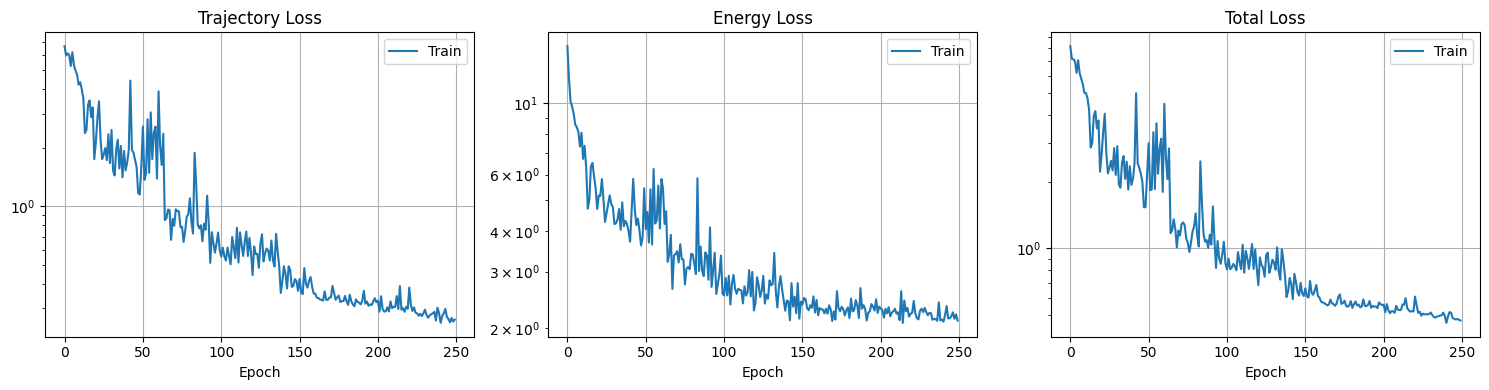

In [192]:
plt.figure(figsize=(15,4))

epochs_axis = range(len(train_q_loss))

plt.subplot(1,3,1)
plt.plot(epochs_axis, train_q_loss, label="Train")
# plt.plot(epochs_axis, val_q_loss, '--', label="Val")
plt.yscale("log")
plt.title("Trajectory Loss")
plt.xlabel("Epoch")
plt.grid(True)
plt.legend()

plt.subplot(1,3,2)
plt.plot(epochs_axis, train_qdot_loss, label="Train")
# plt.plot(epochs_axis, val_loss_energy, '--', label="Val")
plt.yscale("log")
plt.title("Energy Loss")
plt.xlabel("Epoch")
plt.grid(True)
plt.legend()

plt.subplot(1,3,3)
plt.plot(epochs_axis, train_total_loss, label="Train")
# plt.plot(epochs_axis, val_total_loss, '--', label="Val")
plt.yscale("log")
plt.title("Total Loss")
plt.xlabel("Epoch")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()



In [193]:
# -------------------------------------------------
# Which split and which trajectory within it to test
# -------------------------------------------------
split_to_test = test_runs        # or val_runs, train_runs
traj_n        = 1               # index within the chosen split

test_run = split_to_test[traj_n]
seq_len_test = test_run["x"].shape[0] - 1   # full rollout length
print(f"Testing trajectory {traj_n} from split ({seq_len_test} steps)")

test_dataset   = SequenceDataset([test_run], seq_len_test)
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=False, drop_last=False)

dynamics.eval()
for x_seq_batch, u_seq_batch, dq_seq_batch in test_dataloader:
    x_seq_batch  = x_seq_batch.to(device)
    u_seq_batch  = u_seq_batch.to(device)
    dq_seq_batch = dq_seq_batch.to(device)

    q0  = x_seq_batch[:, 0, :q_dim]
    dq0 = dq_seq_batch[:, 0, :]
    x_pred = torch.cat([q0, dq0], dim=-1).clone().detach().requires_grad_(True)

    if use_windowed_rollout:
        preds = rollout_windowed(dynamics, x_pred, u_seq_batch,
                                q_dim, u_dim, dt, seq_len_test)
        preds = [p.detach() for p in preds]
    else:
        preds = []
        for k in range(seq_len_test):
            if k < u_seq_batch.size(1):
                u_step = u_seq_batch[:, k, :]
            else:
                u_step = torch.zeros_like(u_seq_batch[:, 0, :])

            f = lambda tt, xx, u=u_step: dynamics(tt, xx, u)
            x_pred = rk4_step(f, x_pred, k * dt, dt)
            preds.append(x_pred.detach())

# Stack predictions
preds_np = torch.stack(preds, dim=0).squeeze(1).detach().cpu().numpy()  # (T, 4)

pred_traj = {
    "theta1": preds_np[:, 0],
    "theta2": preds_np[:, 1],
    "state3": preds_np[:, 2],
    "state4": preds_np[:, 3],
}

true_traj = {
    "theta1": x_seq_batch[0, 1:, 0].cpu().numpy(),
    "theta2": x_seq_batch[0, 1:, 1].cpu().numpy(),
    "state3": x_seq_batch[0, 1:, 2].cpu().numpy(),
    "state4": x_seq_batch[0, 1:, 3].cpu().numpy(),
}



Testing trajectory 1 from split (3899 steps)


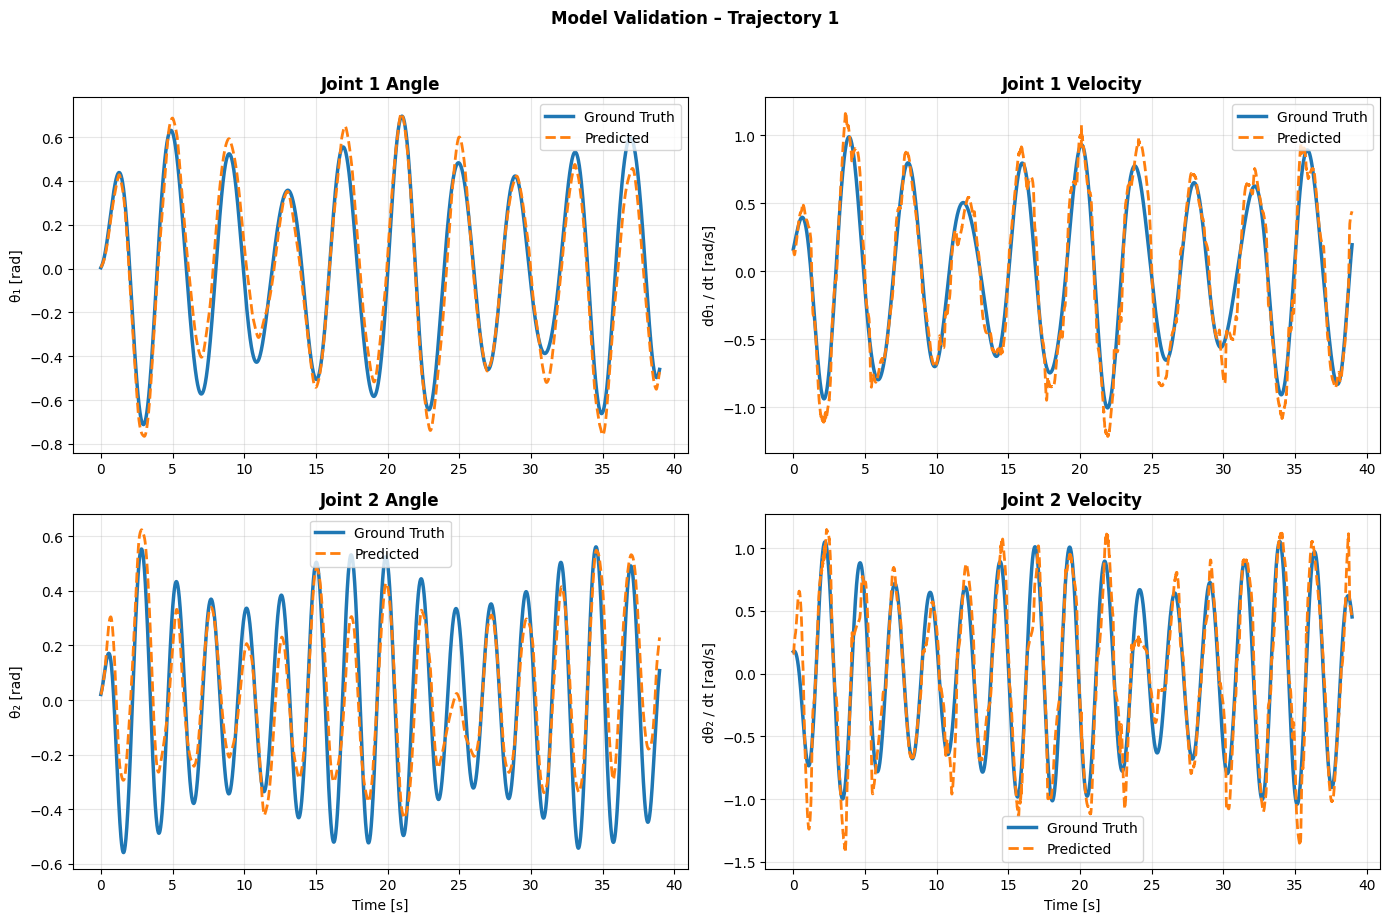


PREDICTION ERROR METRICS
θ₁ RMSE: 0.090358 rad
θ₂ RMSE: 0.135938 rad
dθ₁/dt RMSE: 0.135778 rad/s
dθ₂/dt RMSE: 0.199965 rad/s
θ₁ relative error: 26.65%
θ₂ relative error: 48.86%


In [194]:
import matplotlib.pyplot as plt

# Labels (velocity case)
state3_title = "Joint 1 Velocity"
state3_label = "dθ₁ / dt [rad/s]"
state4_title = "Joint 2 Velocity"
state4_label = "dθ₂ / dt [rad/s]"
# Ensure same horizon
T = min(
    len(pred_traj["theta1"]),
    len(true_traj["theta1"])
)

time = np.arange(T) * dt

fig, axs = plt.subplots(2, 2, figsize=(14, 9))

# -------------------------
# Joint 1 Angle
# -------------------------
axs[0, 0].plot(time, true_traj["theta1"][:T],
               label="Ground Truth", linewidth=2.5)
axs[0, 0].plot(time, pred_traj["theta1"][:T],
               '--', label="Predicted", linewidth=2)
axs[0, 0].set_title("Joint 1 Angle", fontweight='bold')
axs[0, 0].set_ylabel("θ₁ [rad]")
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

# -------------------------
# Joint 1 Velocity
# -------------------------
axs[0, 1].plot(time, true_traj["state3"][:T],
               label="Ground Truth", linewidth=2.5)
axs[0, 1].plot(time, pred_traj["state3"][:T],
               '--', label="Predicted", linewidth=2)
axs[0, 1].set_title("Joint 1 Velocity", fontweight='bold')
axs[0, 1].set_ylabel("dθ₁ / dt [rad/s]")
axs[0, 1].legend()
axs[0, 1].grid(True, alpha=0.3)

# -------------------------
# Joint 2 Angle
# -------------------------
axs[1, 0].plot(time, true_traj["theta2"][:T],
               label="Ground Truth", linewidth=2.5)
axs[1, 0].plot(time, pred_traj["theta2"][:T],
               '--', label="Predicted", linewidth=2)
axs[1, 0].set_title("Joint 2 Angle", fontweight='bold')
axs[1, 0].set_ylabel("θ₂ [rad]")
axs[1, 0].set_xlabel("Time [s]")
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

# -------------------------
# Joint 2 Velocity
# -------------------------
axs[1, 1].plot(time, true_traj["state4"][:T],
               label="Ground Truth", linewidth=2.5)
axs[1, 1].plot(time, pred_traj["state4"][:T],
               '--', label="Predicted", linewidth=2)
axs[1, 1].set_title("Joint 2 Velocity", fontweight='bold')
axs[1, 1].set_ylabel("dθ₂ / dt [rad/s]")
axs[1, 1].set_xlabel("Time [s]")
axs[1, 1].legend()
axs[1, 1].grid(True, alpha=0.3)

plt.suptitle(f"Model Validation – Trajectory {traj_n}",
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ============================================================
# ERROR METRICS
# ============================================================

theta1_rmse = np.sqrt(np.mean(
    (true_traj["theta1"][:T] - pred_traj["theta1"][:T])**2
))
theta2_rmse = np.sqrt(np.mean(
    (true_traj["theta2"][:T] - pred_traj["theta2"][:T])**2
))
state3_rmse = np.sqrt(np.mean(
    (true_traj["state3"][:T] - pred_traj["state3"][:T])**2
))
state4_rmse = np.sqrt(np.mean(
    (true_traj["state4"][:T] - pred_traj["state4"][:T])**2
))

print("\n" + "=" * 60)
print("PREDICTION ERROR METRICS")
print("=" * 60)
print(f"θ₁ RMSE: {theta1_rmse:.6f} rad")
print(f"θ₂ RMSE: {theta2_rmse:.6f} rad")
print(f"dθ₁/dt RMSE: {state3_rmse:.6f} rad/s")
print(f"dθ₂/dt RMSE: {state4_rmse:.6f} rad/s")
print("=" * 60)

# Relative errors
theta1_mean = np.mean(np.abs(true_traj["theta1"][:T]))
theta2_mean = np.mean(np.abs(true_traj["theta2"][:T]))

if theta1_mean > 0:
    print(f"θ₁ relative error: {100 * theta1_rmse / theta1_mean:.2f}%")
if theta2_mean > 0:
    print(f"θ₂ relative error: {100 * theta2_rmse / theta2_mean:.2f}%")
print("=" * 60)

In [190]:
import numpy as np

T = min(len(pred_traj["theta1"]), len(true_traj["theta1"]))

model_name = "LS_sim_no_noise_linear_friction"  # change per model: "LS", "HNN", "baseline", etc.

np.savez(
    f"results_{model_name}.npz",
    model_name=model_name,
    dt=dt,
    traj_n=traj_n,
    # ground truth
    true_theta1=true_traj["theta1"][:T],
    true_theta2=true_traj["theta2"][:T],
    true_dtheta1=true_traj["state3"][:T],
    true_dtheta2=true_traj["state4"][:T],
    # predicted
    pred_theta1=pred_traj["theta1"][:T],
    pred_theta2=pred_traj["theta2"][:T],
    pred_dtheta1=pred_traj["state3"][:T],
    pred_dtheta2=pred_traj["state4"][:T],
)

print(f"Saved results_{model_name}.npz  ({T} steps)")

Saved results_LS_sim_no_noise_linear_friction.npz  (3899 steps)


In [191]:
# Save subnetwork/state (no duplicate keys)
torch.save({
    'mass_nn': mass_nn.state_dict(),
    'diss_nn': diss_nn.state_dict(),
    'actuator_nn': actuator_nn.state_dict(),
}, "HNN_state_quanser_Filt_5N.pth")
print("Saved modular model state to modular_hnn_state.pth")

